# 02 · Perceptron and Linear Separability

**Learning objectives**
1. Describe the perceptron: a neuron with a step activation and a learning rule.
2. Trace one epoch of training by hand and check it against the code.
3. Explain linear separability and the decision boundary.

## 1. Theoretical background

A perceptron predicts $\hat{y} = 1$ if $z \ge 0$ and $0$ otherwise. It learns by correcting its mistakes:

$$\text{error} = t - \hat{y}, \qquad w_i \leftarrow w_i + \eta \cdot \text{error} \cdot x_i, \qquad b \leftarrow b + \eta \cdot \text{error}$$

- $t$ is the target label, $\eta$ the learning rate.
- An **epoch** is one full pass over the training data.

## 2. Linear separability

A dataset is **linearly separable** if one line (a hyperplane in general) puts every positive example on one side and every negative example on the other. The perceptron rule converges on separable data (theoretical result, Rosenblatt 1958; Novikoff 1962). It cannot converge on data that is not separable.

## 3. Hand trace of one epoch (AND gate)

Start with $\mathbf{w} = (0, 0)$, $b = 0$, $\eta = 0.1$. Process the four AND points in order.

| x | t | z | ŷ | error | new w | new b |
|---|---|---|---|---|---|---|
| (0,0) | 0 | 0.0 | 1 | −1 | (0.0, 0.0) | −0.1 |
| (0,1) | 0 | −0.1 | 0 | 0 | (0.0, 0.0) | −0.1 |
| (1,0) | 0 | −0.1 | 0 | 0 | (0.0, 0.0) | −0.1 |
| (1,1) | 1 | −0.1 | 0 | +1 | (0.1, 0.1) | 0.0 |

Two mistakes in epoch 1. The code below reproduces this trace.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from perceptron import Perceptron

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])

# Reproduce the hand trace for one epoch
model = Perceptron(n_features=2, learning_rate=0.1, epochs=1).fit(X, y_and)
print("mistakes in epoch 1:", model.errors_per_epoch)
print("weights after epoch 1:", model.weights, " bias:", round(model.bias, 4))

mistakes in epoch 1: [2]
weights after epoch 1: [0.1 0.1]  bias: 0.0


**Check.** The output should show 2 mistakes in epoch 1 and weights $(0.1, 0.1)$ with bias $0.0$, as in the table.

## 4. Why the update moves the boundary the right way

For one example, after the update the change in $z$ is

$$\Delta z = \eta \cdot \text{error} \cdot (\|\mathbf{x}\|^2 + 1)$$

So a missed positive example ($\text{error} = +1$) raises $z$, and a missed negative example ($\text{error} = -1$) lowers it. The next cell checks this numerically.

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

# State after the first mistake in the hand trace: w=(0,0), b=-0.1.
# z = -0.1 predicts 0 for the positive example (1,1), so error = +1.
w = np.array([0.0, 0.0]); b = -0.1; lr = 0.1
x_i = np.array([1.0, 1.0]); t = 1
z_before = x_i @ w + b
pred = 1 if z_before >= 0 else 0
err = t - pred
w_new = w + lr * err * x_i
b_new = b + lr * err
z_after = x_i @ w_new + b_new
print("z before:", z_before, " error:", err, " z after:", round(float(z_after), 4))
print("predicted change:", lr * err * (x_i @ x_i + 1), " actual change:", round(float(z_after - z_before), 4))

z before: -0.1  error: 1  z after: 0.2
predicted change: 0.30000000000000004  actual change: 0.3


## 5. Decision boundary

The boundary is the set where $w_1 x_1 + w_2 x_2 + b = 0$. Solving for $x_2$ (when $w_2 \ne 0$) gives the line $x_2 = -(w_1 x_1 + b)/w_2$.

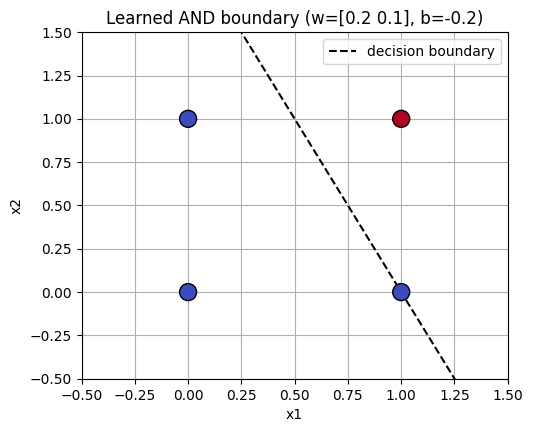

accuracy: 1.0


In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

model = Perceptron(n_features=2, learning_rate=0.1, epochs=20).fit(X, y_and)
w, b = model.weights, model.bias
xs = np.linspace(-0.5, 1.5, 100)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(X[:, 0], X[:, 1], c=y_and, cmap="coolwarm", s=150, edgecolors="black", zorder=3)
ax.plot(xs, -(w[0] * xs + b) / w[1], "k--", label="decision boundary")
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.grid(True)
ax.legend()
ax.set_title(f"Learned AND boundary (w={np.round(w, 2)}, b={round(b, 2)})")
plt.show()
print("accuracy:", model.accuracy(X, y_and))

## 6. Results and observations

- The one-epoch trace matches the hand calculation.
- The predicted and actual change in $z$ agree for the example above.
- The learned boundary separates $(1,1)$ from the other three points.

**Caveat.** The learned weights depend on the learning rate and the order of examples. Another valid solution exists. Rounding can also change a decision for a point lying exactly on the boundary, for example $(1,0)$ in this run.

## 7. Conclusion

The perceptron rule adjusts a single line toward the mistakes. It succeeds when a separating line exists. The next notebook tests this on AND, OR and XOR.

## 8. Exercises

1. Change $\eta$ to $0.5$ and repeat the one-epoch trace. How do the weights change? Does the set of mistakes change?
2. Prove that for $\mathbf{w} = (0, 0)$ the first update always has $\Delta b = \eta \cdot \text{error}$.
3. Find a separating line for OR by hand, without training.